In [24]:
import torch
from GAN.src.model import build_res_unet, MainModel
from GAN.src.colorize import test_colorizer, colorize
from GAN.src.visualize import visualize_gan
from CNN.src.visualize import visualize_cnn
# from CNN.src.model import build_colorization_model
from src.evaluate import avg_deltaE, mean_chroma, mse
from prettytable import PrettyTable

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Visualizations

### CNN

In [17]:
# Load model

# Define image size
img_size = 256

# Create the model
model = build_colorization_model(input_shape=(img_size, img_size, 1))

# Load weights from the .h5 file
model.load_weights("CNN/checkpoints/colorization-faces-unet-0.009.h5")

# Check if the model loaded correctly
model.summary()


NameError: name 'build_colorization_model' is not defined

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 286ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step


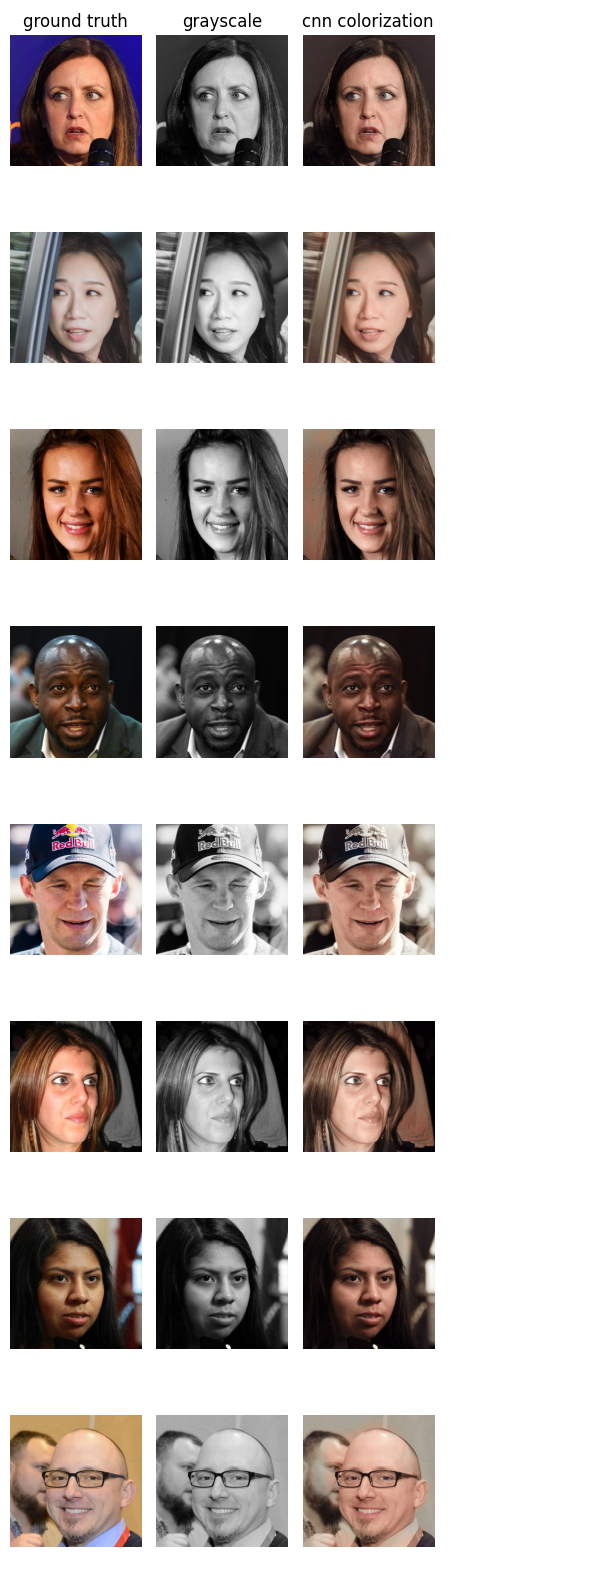

In [4]:
visualize_cnn(model, val_path="data/faces_val", num_images = 8, seed = 33)

### cGAN

In [ ]:
# load generators
net_G1 = build_res_unet(n_input=1, n_output=2, size=256)
net_G1.load_state_dict(torch.load("GAN/src/checkpoints/res18-unet.pt", map_location=device))

net_G2 = build_res_unet(n_input=1, n_output=2, size=256)
net_G2.load_state_dict(torch.load("GAN/src/checkpoints/res18-unet.pt", map_location=device))

<All keys matched successfully>

In [ ]:
# base model
model1 = MainModel(net_G = net_G1)
model1.load_state_dict(torch.load("GAN/src/checkpoints/final_model_weights.pt", map_location=device))

model initialized with norm initialization


<All keys matched successfully>

In [ ]:
# finetuned model
model2 = MainModel(net_G = net_G2)
model2.load_state_dict(torch.load("GAN/src/checkpoints/fine_tuned_faces.pt", map_location=device))

model initialized with norm initialization


<All keys matched successfully>

In [ ]:
visualize_gan(model1,model2, val_path="data/faces_val", num_images= 8, seed = 33)

# Evaluation

In [21]:
# CIEDE2000 Delta E score
#cnn_deltae = avg_deltaE(model, "data/faces_val", model_type="CNN", seed = 13, size = 50)
gan1_deltae = avg_deltaE(model1, "data/faces_val", model_type="GAN", seed = 13, size = 10)
gan2_deltae = avg_deltaE(model2, "data/faces_val", model_type="GAN", seed = 13, size = 10)

100%|██████████| 10/10 [00:09<00:00,  1.08it/s]

CIEDE2000 Delta E scores	 - 	 CNN: 0,	 GAN: 11.987554070035271


In [ ]:
cnn_chroma = mean_chroma(model, "data/faces_val", model_type="CNN", seed = 13, size = 50)
gan1_chroma = mean_chroma(model1, "data/faces_val", model_type="GAN", seed = 13, size = 50)
gan2_chroma = mean_chroma(model2, "data/faces_val", model_type="GAN", seed = 13, size = 50)

In [ ]:
cnn_mse = mse(model, "data/faces_val", model_type="CNN", seed = 13, size = 50)
gan1_mse = mse(model1, "data/faces_val", model_type="GAN", seed = 13, size = 50)
gan2_mse = mse(model2, "data/faces_val", model_type="GAN", seed = 13, size = 50)

In [25]:
evals = PrettyTable()
evals.field_names = ["metric", "CNN", "base GAN", "finetuned GAN"]
evals.add_row(["CIDE 2000 Delta E", 0, 0, 0])
evals.add_row(["mean average chroma", 0, 0, 0])
evals.add_row(["MSE", 0, 0, 0])
print(evals)

+---------------------+-----+----------+---------------+
|        metric       | CNN | base GAN | finetuned GAN |
+---------------------+-----+----------+---------------+
|  CIDE 2000 Delta E  |  0  |    0     |       0       |
| mean average chroma |  0  |    0     |       0       |
|         MSE         |  0  |    0     |       0       |
+---------------------+-----+----------+---------------+
